# Maxwell's Molecular Vortices, Worked Through

A short study notebook on J. C. Maxwell, *On Physical Lines of Force* (Philosophical Magazine, 1861–62). It covers the first three parts of the paper, one idea each, and ends where the Vibrating-Fluid experiments begin.

| Part | Maxwell's idea | What you compute | Course links |
|---|---|---|---|
| 1 | Spinning vortices make a stress (Part I) | The squeeze inside a wire, from stresses alone | Theory of Elasticity, PDEs |
| 2 | Idle wheels between vortices carry the current (Part II) | The current for four spin patterns, as in experiment 9 | Discrete Mathematical Modeling, PDEs |
| 3 | Elastic cells carry waves at the speed of light (Part III) | The lattice wave equation, its speed and its dispersion | PDEs, Numerical Matrix Analysis, Linear Statistical Models |

**How to use it.** Read a part, run its cells, then try the exercises marked **Try it**. Each part takes about an hour. All cells together run in a few seconds and need only `numpy`, `scipy` and `matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, linalg, integrate

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2), "font.size": 11, "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["k", "0.45", "0.7"]), "image.cmap": "Greys",
    "axes.spines.top": False, "axes.spines.right": False,
})
rng = np.random.default_rng(1861)

---
## Part 1. Maxwell's vortex stress (1861, Part I)

**Maxwell's picture.** Space is full of small vortices. Each vortex spins about an axis along the magnetic force $\boldsymbol{\alpha}$ (Step 3 explains $\boldsymbol\alpha$). A spinning vortex flings its fluid outward, like a spinning bucket of water, so it pushes on its neighbors from the side. Along its axis it does not. So the medium pushes harder across the lines of force than along them.

Maxwell turns that picture into a **stress**, then into a **force**. This part rebuilds the elasticity needed for both steps (Steps 1–5), then checks the result on a wire.

### Step 1. What a stress is

**Stress is force per unit area.** Pull a straight rod with a force $F$ at each end. Cut it anywhere across its length. The top part pulls on the bottom part with the same force $F$, spread over the cross-section area $A$. The stress is

$$\sigma = \frac{F}{A}.$$

A thick rod and a thin rod pulled with the same $F$ carry the same force, but the thin one has the larger stress. Stress tells how hard each bit of the cut is pulled.

**Stress depends on which way the cut faces.** Cut the same rod along its length instead of across it. The two halves sit side by side, and nothing pulls one away from the other. So one number is not enough: the force per area depends on the direction of the cut.

To keep track, describe a cut by its unit normal $\mathbf{n}$, the arrow that points straight out of the cut. The force per unit area on that cut is a vector $\mathbf{t}$, the **traction**. The stress $\sigma$ is the table of numbers that turns the normal into the traction:

$$t_i = \sigma_{ij}\,n_j \qquad (\text{sum over the repeated index } j).$$

In 2D, $\sigma$ is a $2\times2$ table:

- $\sigma_{xx}$: the push or pull straight across a cut that faces $x$. Positive means **tension** (the two sides pull on each other). Negative means **pressure** (they push).
- $\sigma_{xy} = \sigma_{yx}$: a sideways drag along the cut (**shear**). The table is symmetric, or a small square would spin up on its own.

Two examples to keep in mind:

- **A gas at pressure $p$.** A gas pushes equally in every direction and never drags sideways. So its table has $-p$ on the diagonal and zeros elsewhere:
$$\sigma = \begin{bmatrix}-p & 0\\ 0 & -p\end{bmatrix} = -p\,I ,$$
where $I$ is the identity table. The minus sign means push (positive means pull). Take a cut facing $x$, so $\mathbf n = (1, 0)$. The force on it is $\mathbf t = \sigma\mathbf n = (-p,\ 0)$: strength $p$, pointing back into the cut, against $\mathbf n$. A cut facing any other way gives the same: $\mathbf t = -p\,\mathbf n$, a push of strength $p$ straight into the cut, never sideways.

  In index form the identity table is the **Kronecker delta**: $\delta_{ij} = 1$ when $i = j$, and $\delta_{ij} = 0$ when $i \neq j$. So the gas stress is $\sigma_{ij} = -p\,\delta_{ij}$. Multiplying a number by $\delta_{ij}$ puts it on the diagonal only: an equal push on every face, no shear. Summing with $\delta$ just renames an index, $\delta_{ij}\,v_j = v_i$, because only the term with $j = i$ survives.
- **A rope** pulled with tension $T$ along the unit vector $\mathbf{e}$: $\sigma_{ij} = T\,e_i e_j$. For a rope along $y$, $\mathbf e = (0, 1)$, this is $\begin{bmatrix}0 & 0\\ 0 & T\end{bmatrix}$, the rod in the figure below. A cut across the rope ($\mathbf{n} = \mathbf{e}$) feels $\mathbf{t} = T\mathbf{e}$: a pull of strength $T$. A cut along the rope ($\mathbf{n}\perp\mathbf{e}$) feels nothing.

**The table in 2D.** The stress at a point is four numbers. Each one answers: *on a cut facing this way, how hard is the force pushing that way?*

$$\sigma = \begin{bmatrix}\sigma_{xx} & \sigma_{xy}\\ \sigma_{yx} & \sigma_{yy}\end{bmatrix} = \begin{bmatrix}\sigma_{x} & \tau_{xy}\\ \tau_{yx} & \sigma_{y}\end{bmatrix}$$

The diagonal entries ($\sigma_x$, $\sigma_y$) pull or push straight across a face: **normal stress**. The off-diagonal entries ($\tau_{xy} = \tau_{yx}$) drag along a face: **shear stress**. In 3D the table grows to $3\times3$ (the Cauchy stress tensor). The 2D table is its top-left block, used when nothing changes along $z$. Since the table is symmetric, it does not matter whether rows or columns are read as "the face".

The figure below draws the table on a small square of material:

- **(a)** a general state: normal arrows on every face, plus shear arrows along them;
- **(b)** the rod pulled along $y$, $\sigma = \begin{bmatrix}0 & 0\\ 0 & F/A\end{bmatrix}$: only the top and bottom faces are pulled;
- **(c)** Maxwell's medium with the field along $y$: the same pull along the field lines, plus an equal push on the side faces;
- **(d)** the rod again, cut at 45°: the force on the slanted cut, $\mathbf t = \sigma\mathbf n$, splits into a part straight across the cut (normal) and a part along it (shear).

Arrows pointing **away** from a face mean tension (pull). Arrows pointing **into** a face mean pressure (push).

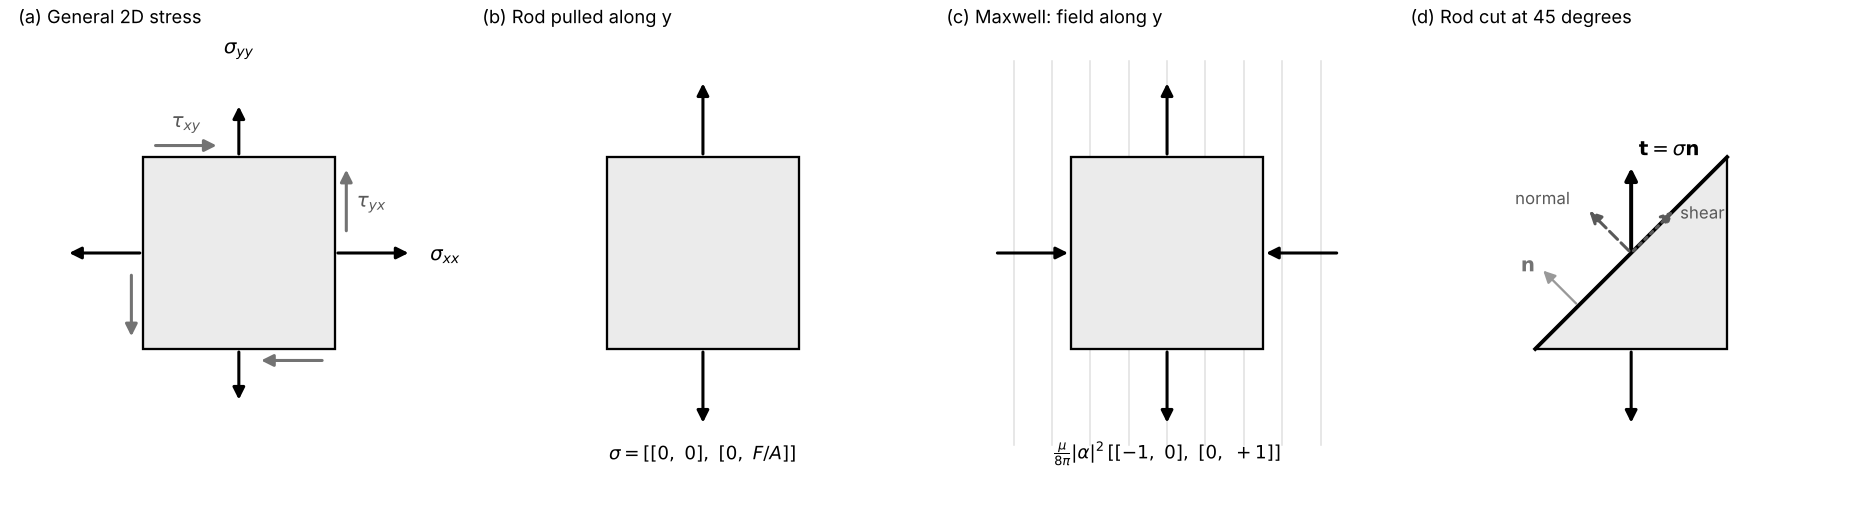

### Step 2. A stress that changes from place to place pushes the material

Stress is force per area, so the force on a face is **stress × face area**. Take a small square of size $dx \times dy$, one unit thick. Its right and left faces each have area $dy$. Its top and bottom faces each have area $dx$.

- Right face (normal $+\hat{\mathbf x}$): force $+\sigma_{xx}(x + dx)\,dy$ in the $x$ direction.
- Left face (normal $-\hat{\mathbf x}$): force $-\sigma_{xx}(x)\,dy$. Same stress table, but the face points the other way, so the force flips sign.
- Top and bottom faces: the shear $\sigma_{xy}$ adds forces $+\sigma_{xy}(y + dy)\,dx$ and $-\sigma_{xy}(y)\,dx$ in the $x$ direction.

Add the four. The net $x$ force on the square is

$$dF_x = \big[\sigma_{xx}(x+dx) - \sigma_{xx}(x)\big]dy + \big[\sigma_{xy}(y+dy) - \sigma_{xy}(y)\big]dx \;\approx\; \Big(\frac{\partial \sigma_{xx}}{\partial x} + \frac{\partial \sigma_{xy}}{\partial y}\Big)\,dx\,dy .$$

The product $dx\,dy = dA$ is the area of the square. So the net force is a number times $dA$:

$$dF_i = f_i\,dA, \qquad f_i = \partial_j\,\sigma_{ij}, \qquad \mathbf{f} = \nabla\cdot\sigma, \qquad\text{the divergence of the stress.}$$

$f_i$ is the force on the square per unit of its area. (In 3D the square becomes a box, $dA$ becomes the volume $dV = dx\,dy\,dz$, and $f_i$ is the force per unit volume.)

A uniform stress gives no force: opposite faces pull equally. Only a change in stress pushes. For a gas, $\sigma = -pI$ gives $\mathbf f = \nabla\cdot(-pI) = -\nabla p$: the gas pushes from high pressure to low. This is the pressure term of the Navier–Stokes equations.

**Course link: Theory of Elasticity. From the balance law to waves.** In Maxwell's medium the stress comes from the field $\boldsymbol\alpha$. In an elastic solid it comes from how much the material is stretched. The balance law is the same. Here it is, followed all the way to the wave equation.

**(i) Index form.** Let $u_i(\mathbf x, t)$ be the displacement of the material (how far each bit has moved from where it started). Add a body force $b_i$ per unit volume, such as weight. If the material is at rest, the forces balance:

$$\partial_j\sigma_{ij} + b_i = 0 \qquad (\text{equilibrium}).$$

If they do not balance, Newton's second law applies to each unit volume, with mass $\rho$ and acceleration $\ddot u_i = \partial^2 u_i/\partial t^2$:

$$\rho\,\ddot u_i = \partial_j\sigma_{ij} + b_i \qquad (\text{motion}).$$

**(ii) Vector form.** Each value of $i$ ($x$, $y$ or $z$) gives one equation. The term $\partial_j\sigma_{ij}$ is the $i$-th component of $\nabla\cdot\sigma$. So the three equations pack into

$$\nabla\cdot\sigma + \mathbf b = \mathbf 0 \quad (\text{equilibrium}), \qquad \rho\,\ddot{\mathbf u} = \nabla\cdot\sigma + \mathbf b \quad (\text{motion}).$$

**(iii) Waves in a rod (1D).** Go back to the rod and let it vibrate along its length. The strain is the stretch per unit length, $\varepsilon = \partial u/\partial x$. Hooke's law says the stress follows the strain: $\sigma = E\,\varepsilon = E\,\partial u/\partial x$, with $E$ the stiffness (Young's modulus). Drop the body force. The motion equation becomes

$$\rho\,\frac{\partial^2 u}{\partial t^2} = \frac{\partial}{\partial x}\Big(E\,\frac{\partial u}{\partial x}\Big) = E\,\frac{\partial^2 u}{\partial x^2} \quad\Longrightarrow\quad \frac{\partial^2 u}{\partial x^2} = \frac{1}{c^2}\,\frac{\partial^2 u}{\partial t^2}, \qquad c = \sqrt{E/\rho}.$$

This is the wave equation. The stiffness pushes, the density resists, and their ratio sets the speed. For steel, $E \approx 200$ GPa and $\rho \approx 7850$ kg/m³, so $c \approx 5000$ m/s.

**(iv) Waves in 3D.** For a solid that behaves the same in every direction, Hooke's law reads

$$\sigma_{ij} = \lambda\,\varepsilon_{kk}\,\delta_{ij} + 2G\,\varepsilon_{ij}, \qquad \varepsilon_{ij} = \tfrac12\big(\partial_i u_j + \partial_j u_i\big),$$

with $\lambda$ and $G$ the two Lamé constants. ($G$ is the shear stiffness. Books often call it $\mu$; this notebook saves $\mu$ for Maxwell.) The term $\lambda\,\varepsilon_{kk}\,\delta_{ij}$ is an equal push or pull on every face, set by $\varepsilon_{kk} = \varepsilon_{xx} + \varepsilon_{yy} + \varepsilon_{zz} = \nabla\cdot\mathbf u$, the change in volume. Take the divergence, term by term:

- $\partial_j\big(\lambda\,\varepsilon_{kk}\,\delta_{ij}\big) = \lambda\,\partial_i(\partial_k u_k) = \lambda\,\partial_i(\nabla\cdot\mathbf u)$. The $\delta_{ij}$ keeps only the term with $j = i$, so $\partial_j$ becomes $\partial_i$.
- $\partial_j\big(2G\,\varepsilon_{ij}\big) = G\,\big(\partial_i\partial_j u_j + \partial_j\partial_j u_i\big) = G\,\partial_i(\nabla\cdot\mathbf u) + G\,\nabla^2 u_i$.

So, with no body force,

$$\rho\,\ddot{\mathbf u} = (\lambda + G)\,\nabla(\nabla\cdot\mathbf u) + G\,\nabla^2\mathbf u \qquad (\text{the Navier–Cauchy equation}).$$

Two kinds of wave come out of it:

- **Shear (transverse) waves.** The material slides sideways without being squeezed, so $\nabla\cdot\mathbf u = 0$. Then $\nabla^2\mathbf u = \dfrac{1}{c_s^2}\,\ddot{\mathbf u}$, with $c_s = \sqrt{G/\rho}$.
- **Compression (longitudinal) waves.** The material is squeezed without turning, so $\nabla\times\mathbf u = 0$ and $\nabla(\nabla\cdot\mathbf u) = \nabla^2\mathbf u$. Then $\nabla^2\mathbf u = \dfrac{1}{c_p^2}\,\ddot{\mathbf u}$, with $c_p = \sqrt{(\lambda + 2G)/\rho}$.

**Why this matters for Maxwell.** In Part III, Maxwell treats light as a shear wave in his elastic medium. He computes its speed the same way as $c_s$: from the medium's shear stiffness and its density. Part 3 of this notebook builds the lattice version of that wave.

### Step 3. Maxwell's stress

**What $\boldsymbol\alpha$ is.** Maxwell names the magnetic force at a point by its three components, $\alpha$, $\beta$, $\gamma$. This notebook packs them into one arrow, $\boldsymbol\alpha = (\alpha, \beta, \gamma)$, and writes $\alpha_i$ for its $i$-th component. Its length is $|\boldsymbol\alpha| = \sqrt{\alpha^2 + \beta^2 + \gamma^2}$ (panel (b) below). In Maxwell's model the arrow has a mechanical meaning (panel (a)):

- its **direction** is the axis of the vortices at that point, which is also the direction of the line of force;
- its **length** $|\boldsymbol\alpha|$ is the speed of the vortex rims.

The coefficient $\mu$ is the density of the vortex medium. In today's notation, $\boldsymbol\alpha$ is the magnetic field $\mathbf H$, $\mu$ is the magnetic permeability, and $\mu\boldsymbol\alpha$ is the magnetic induction $\mathbf B$.

**The stress.** Maxwell finds (Prop. II) that the pressure across the lines of force exceeds the pressure along them by $\tfrac{\mu}{4\pi}|\boldsymbol\alpha|^2$. Here $\mu$ plays the density of the vortex medium and $|\boldsymbol\alpha|$ the speed of the vortex rims, so the excess is "density times speed squared", like the pressure in a spinning bucket. As a stress:

$$\sigma_{ij} = \underbrace{\frac{\mu}{4\pi}\,\alpha_i\alpha_j}_{\text{a rope along }\boldsymbol\alpha} \;-\; \underbrace{p_1\,\delta_{ij}}_{\text{a gas}} .$$

The schematic shows (a) what $\boldsymbol\alpha$ means for one vortex, (b) its three components $\alpha$, $\beta$, $\gamma$, (c) how a bundle of vortices pushes sideways and pulls along its length, and (d) how the two terms of the stress add up on a small square.

![Maxwell's vortices and stress: (a) one vortex, alpha along its axis with length equal to the rim speed; (b) the three components of alpha; (c) vortex tubes along the field push sideways and pull along their length; (d) rope term plus gas term equals Maxwell's stress.](attachment:maxwell_stress.png)
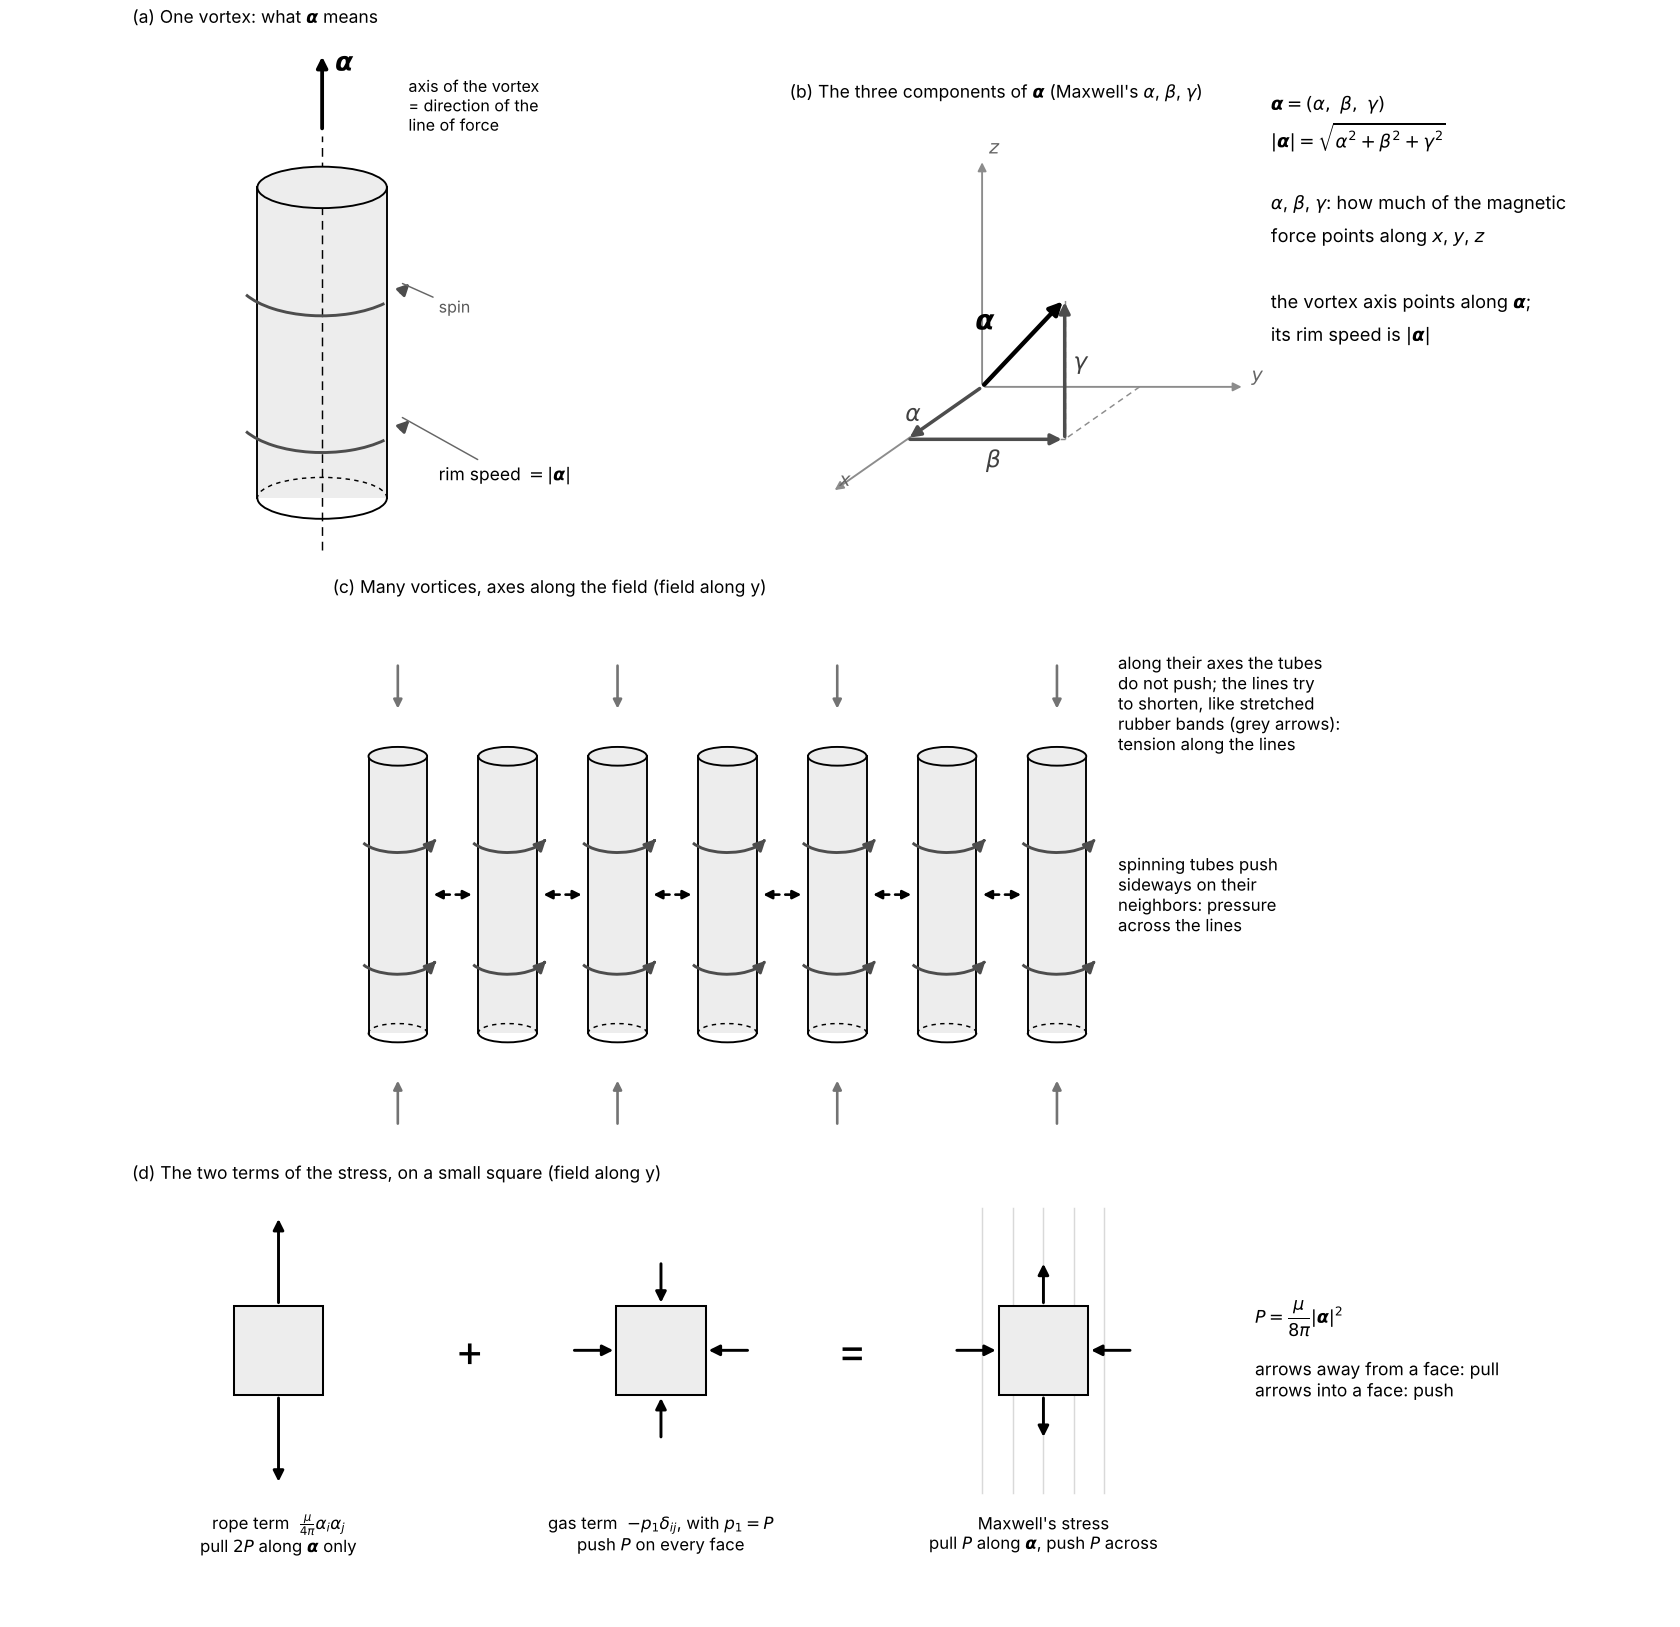

The first term is the rope of Step 1 with $\mathbf e = \boldsymbol\alpha/|\boldsymbol\alpha|$ and $T = \tfrac{\mu}{4\pi}|\boldsymbol\alpha|^2$. The second is a plain pressure $p_1$ in all directions. Maxwell leaves $p_1$ general. The choice $p_1 = \tfrac{\mu}{8\pi}|\boldsymbol\alpha|^2$ gives the modern **Maxwell stress**, and this notebook uses it. With it:

- along the lines of force: a **tension** $\tfrac{\mu}{8\pi}|\boldsymbol\alpha|^2$ (the lines try to shorten);
- across the lines: a **pressure** of the same size (the lines push each other apart).

That is Faraday's picture of lines of force, as rubber bands that pull along their length and push sideways. The cell below checks it: it computes the traction on cuts at several angles for a field along $x$.

In [2]:
def maxwell_stress(alpha, mu_over_4pi=1.0):
    alpha = np.asarray(alpha, float)
    return mu_over_4pi*(np.outer(alpha, alpha) - 0.5*(alpha @ alpha)*np.eye(2))

S = maxwell_stress([1.0, 0.0])                     # field along x, |alpha| = 1
print("stress table:\n", S)
for deg in (0, 45, 90):
    nvec = np.array([np.cos(np.radians(deg)), np.sin(np.radians(deg))])
    t = S @ nvec
    print(f"cut normal at {deg:2d} deg: traction = {t.round(3)},  normal part t.n = {t @ nvec:+.3f}  ({'tension' if t @ nvec > 1e-12 else 'pressure' if t @ nvec < -1e-12 else 'shear only'})")

stress table:
 [[ 0.5  0. ]
 [ 0.  -0.5]]
cut normal at  0 deg: traction = [0.5 0. ],  normal part t.n = +0.500  (tension)
cut normal at 45 deg: traction = [ 0.354 -0.354],  normal part t.n = +0.000  (shear only)
cut normal at 90 deg: traction = [ 0.  -0.5],  normal part t.n = -0.500  (pressure)


A cut across the field lines (normal at 0°) feels a pull of $+0.5$: tension. A cut along them (normal at 90°) feels a push of $-0.5$: pressure. At 45° the normal part vanishes and only shear is left.

### Step 4. From the stress to the force

Apply Step 2 to Maxwell's stress:

$$f_i = \partial_j\sigma_{ij} = \frac{\mu}{4\pi}\,\partial_j(\alpha_i\alpha_j) \;-\; \partial_i p_1 .$$

**(a) Product rule** on the first term:

$$\partial_j(\alpha_i\alpha_j) = \alpha_i\,(\partial_j\alpha_j) + \alpha_j\,\partial_j\alpha_i = \alpha_i\,(\nabla\cdot\boldsymbol\alpha) + \big[(\boldsymbol\alpha\cdot\nabla)\boldsymbol\alpha\big]_i .$$

**(b) The pressure term.** With $p_1 = \tfrac{\mu}{8\pi}|\boldsymbol\alpha|^2$:

$$\partial_i p_1 = \frac{\mu}{4\pi}\,\alpha_j\,\partial_i\alpha_j = \frac{\mu}{4\pi}\Big[\nabla\big(\tfrac12|\boldsymbol\alpha|^2\big)\Big]_i .$$

**(c) A vector identity:**

$$\nabla\big(\tfrac12|\boldsymbol\alpha|^2\big) = (\boldsymbol\alpha\cdot\nabla)\boldsymbol\alpha + \boldsymbol\alpha\times(\nabla\times\boldsymbol\alpha).$$

Check it in 2D. Write $\boldsymbol\alpha = (a, b)$ and $\nabla\times\boldsymbol\alpha = \omega\,\hat{\mathbf z}$ with $\omega = \partial_x b - \partial_y a$. Then $\boldsymbol\alpha\times(\omega\hat{\mathbf z}) = (b\,\omega,\; -a\,\omega)$. The $x$ parts: left side $a\,\partial_x a + b\,\partial_x b$; first term on the right $a\,\partial_x a + b\,\partial_y a$. Their difference is $b(\partial_x b - \partial_y a) = b\,\omega$, which is the $x$ part of the last term.

**(d) Put (a), (b), (c) together.** The $(\boldsymbol\alpha\cdot\nabla)\boldsymbol\alpha$ terms cancel:

$$\boxed{\;\mathbf{f} = \frac{\mu}{4\pi}\Big[\boldsymbol{\alpha}\,(\nabla\cdot\boldsymbol{\alpha}) \;-\; \boldsymbol{\alpha}\times(\nabla\times\boldsymbol{\alpha})\Big]\;}$$

- The first term needs $\nabla\cdot\boldsymbol\alpha \neq 0$: a magnetic "pole". It pushes poles along the field.
- The second term needs $\nabla\times\boldsymbol\alpha \neq 0$. In Part II Maxwell shows that $\nabla\times\boldsymbol\alpha$ is the electric current. So this term is the force on a current. Since $-\boldsymbol\alpha\times\mathbf J = \mathbf J\times\boldsymbol\alpha$, it is the familiar $\mathbf J\times\mathbf B$.
- With a general $p_1$, one more term appears: $-\nabla\big(p_1 - \tfrac{\mu}{8\pi}|\boldsymbol\alpha|^2\big)$, an ordinary pressure gradient.

### Step 5. The wire, by hand

Let a round wire of radius $a$ carry a uniform current. Take $\mu/4\pi = 1$ and let $J$ stand for $\nabla\times\boldsymbol\alpha$ inside the wire.

**Inside** ($r < a$): $\boldsymbol\alpha = \tfrac{J}{2}(-y,\,x)$.

- $\nabla\cdot\boldsymbol\alpha = \partial_x(-\tfrac{J}{2}y) + \partial_y(\tfrac{J}{2}x) = 0$: no poles.
- $\omega = \partial_x(\tfrac{J}{2}x) - \partial_y(-\tfrac{J}{2}y) = J$.
- $\boldsymbol\alpha\times(J\hat{\mathbf z}) = (\alpha_y J,\; -\alpha_x J) = \tfrac{J^2}{2}(x,\; y)$.
- So $\mathbf f = -\tfrac{J^2}{2}(x,\; y)$: it points to the axis and grows with distance from it.

At $x = 0.5$ with $J = 1$: $f_x = -0.25$. The next code cell prints this number from the stress grid.

**Outside** ($r > a$): $\boldsymbol\alpha = \tfrac{Ja^2}{2}\,\dfrac{(-y,\,x)}{r^2}$.

- $\nabla\cdot\boldsymbol\alpha = 0$ again.
- $\omega = \tfrac{Ja^2}{2}\big[\partial_x(x/r^2) + \partial_y(y/r^2)\big] = \tfrac{Ja^2}{2}\,\dfrac{(r^2 - 2x^2) + (r^2 - 2y^2)}{r^4} = 0$.
- So $\mathbf f = 0$: outside the wire the tension along the circles and the pressure across them balance exactly.

The picture: the circular lines of force act like rubber bands around a bundle. Their tension squeezes the wire. This is the **pinch effect**.

**Check.** The cell below builds Maxwell's stress on a grid, takes its divergence numerically (Step 2), and compares with the boxed formula (Step 4).

largest error, divergence of stress vs formula: 0.00029
inside the wire the force points to the axis: f = -0.25 at x = 0.5


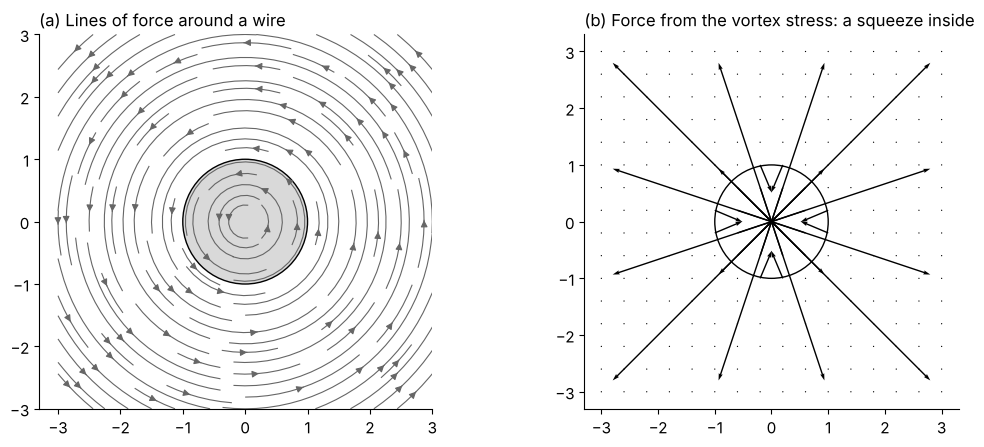

In [3]:
n, L = 241, 3.0
x = np.linspace(-L, L, n); h = x[1] - x[0]
X, Y = np.meshgrid(x, x, indexing="xy")          # arrays [iy, ix]
R2 = X**2 + Y**2
a, J = 1.0, 1.0                                    # wire radius, current density

def wire_field(H0=0.0):
    inside = R2 < a**2
    Hx = np.where(inside, -J/2*Y, -J*a**2/2*Y/np.maximum(R2, 1e-12)) + H0
    Hy = np.where(inside,  J/2*X,  J*a**2/2*X/np.maximum(R2, 1e-12))
    return Hx, Hy

def maxwell_force(Hx, Hy):
    p1 = 0.5*(Hx**2 + Hy**2)                       # mu H^2 / 8 pi with mu/4pi = 1
    sxx, sxy, syy = Hx*Hx - p1, Hx*Hy, Hy*Hy - p1
    d = lambda f: np.gradient(f, h)                 # returns (d/dy, d/dx)
    fx = d(sxx)[1] + d(sxy)[0]
    fy = d(sxy)[1] + d(syy)[0]
    return fx, fy

Hx, Hy = wire_field()
fx, fy = maxwell_force(Hx, Hy)
curl = np.gradient(Hy, h)[1] - np.gradient(Hx, h)[0]
fx_th, fy_th = -Hy*curl, Hx*curl                  # -alpha x (curl alpha), no poles here
ok = (np.sqrt(R2) < 0.85) | (np.sqrt(R2) > 1.15)  # skip the jump at the wire surface
print("largest error, divergence of stress vs formula:", np.abs(fx - fx_th)[ok].max().round(5))
print("inside the wire the force points to the axis: f =", (fx[n//2, n//2 + 20]).round(3), "at x =", x[n//2 + 20].round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].streamplot(x, x, Hx, Hy, color="0.4", density=1.1, linewidth=0.8)
ax[0].add_patch(plt.Circle((0, 0), a, fc="0.85", ec="k"))
ax[0].set_title("(a) Lines of force around a wire"); ax[0].set_aspect("equal")
s = slice(None, None, 16)
ax[1].quiver(X[s, s], Y[s, s], fx[s, s], fy[s, s], color="k")
ax[1].add_patch(plt.Circle((0, 0), a, fc="none", ec="k"))
ax[1].set_title("(b) Force from the vortex stress: a squeeze inside"); ax[1].set_aspect("equal")
plt.tight_layout(); plt.show()

Inside the wire the force points toward the axis. The tension along the circular lines of force squeezes the wire (the "pinch effect"). Outside the wire the force is zero: there the pressure and the tension balance.

**Try it 1.1.** Add a uniform field $H_0$ along $x$ with `wire_field(H0=0.5)`. Integrate $f_y$ over the wire's disk with `(fy*(R2 < a**2)).sum()*h*h`. Compare with $J\,\pi a^2 H_0$. This is the force on a wire in a magnet, obtained from stresses alone. *Hint:* by Step 4, $\mathbf f = -\boldsymbol\alpha\times(J\hat{\mathbf z})$ inside. The wire's own field gives zero net force by symmetry. The added field gives $-(H_0\hat{\mathbf x})\times(J\hat{\mathbf z}) = H_0 J\,\hat{\mathbf y}$ at every point of the disk. The grid answer comes within about 1%, because the grid's disk is not quite round.

**Try it 1.2.** Show that a uniform field gives no force anywhere. Which term of the identity vanishes, and why?

---
## Part 2. Idle wheels and electric current (1861, Part II)

**The problem.** Two neighboring vortices that spin the same way have touching surfaces that move in opposite directions. They would grind. Maxwell fixes this with a layer of small particles between the vortices, like idle wheels in a machine. Each particle rolls between two vortices and moves at the **mean** of the two surface speeds.

**The result.** Where all vortices spin at the same rate, the two surface speeds cancel and the particles stay still. Where the spin changes from place to place, the particles drift. Maxwell identifies that drift as the electric current, proportional to $\nabla\times\boldsymbol{\alpha}$ (Prop. V).

**On a lattice.** Take square cells of radius $R$ on spacing 1, with spin $\Omega_{ij}$ (counterclockwise positive). At the contact between a left cell $i$ and a right cell $i+1$, the left rim moves up at $\Omega_i R$ and the right rim moves down at $\Omega_{i+1} R$. The particle there moves up at

$$v_y = \tfrac{R}{2}\,(\Omega_i - \Omega_{i+1}) \;\approx\; -\tfrac{R}{2}\,\partial_x \Omega .$$

The same rule on horizontal contacts gives $v_x \approx \tfrac{R}{2}\partial_y\Omega$. Together $\mathbf{v} = \tfrac{R}{2}\nabla\times(\Omega\,\hat{\mathbf{z}})$: a discrete curl. In experiment 9 the fluid in the gaps between the vibrating shells plays these particles.

**Course link: Discrete Mathematical Modeling, PDEs.** The idle-wheel rule is a finite-difference curl. Summing it along a line telescopes, which is a discrete Stokes theorem.

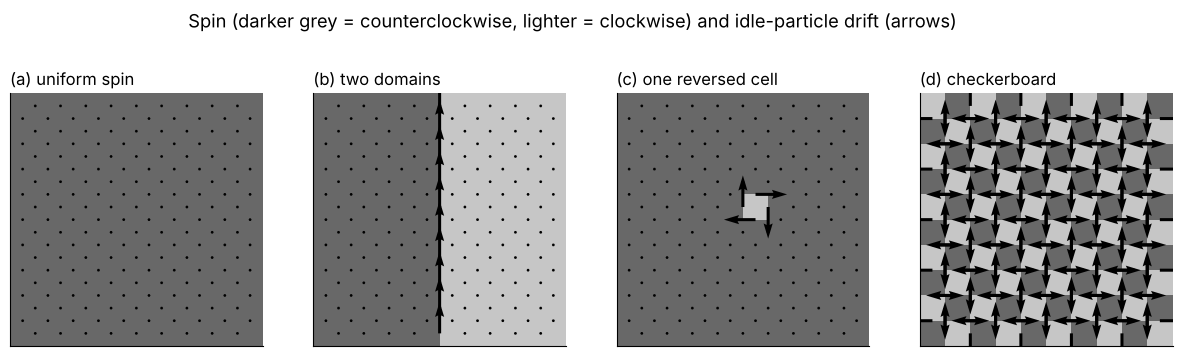

Total drift across row j=3: 0.5   (R/2)(spin at left end - spin at right end): 0.5


In [4]:
def idle_particles(Om, R=0.5):
    # Om[i, j]: i = x index, j = y index
    vy = 0.5*R*(Om[:-1, :] - Om[1:, :])     # vertical contacts, between (i,j) and (i+1,j)
    vx = 0.5*R*(Om[:, 1:] - Om[:, :-1])     # horizontal contacts, between (i,j) and (i,j+1)
    return vx, vy

N = 10
I_, J_ = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")
patterns = {
    "(a) uniform spin": np.ones((N, N)),
    "(b) two domains": np.where(I_ < N//2, 1.0, -1.0),
    "(c) one reversed cell": np.where((I_ == N//2) & (J_ == N//2), -1.0, 1.0),
    "(d) checkerboard": np.where((I_ + J_) % 2 == 0, 1.0, -1.0),
}
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for ax, (name, Om) in zip(axs, patterns.items()):
    vx, vy = idle_particles(Om)
    ax.imshow(Om.T, origin="lower", cmap="Greys", vmin=-3, vmax=3, extent=(-0.5, N-0.5, -0.5, N-0.5))
    xi, yj = np.meshgrid(np.arange(N-1) + 0.5, np.arange(N), indexing="ij")
    ax.quiver(xi, yj, 0*vy, vy, scale=4, color="k", width=0.012)
    xi, yj = np.meshgrid(np.arange(N), np.arange(N-1) + 0.5, indexing="ij")
    ax.quiver(xi, yj, vx, 0*vx, scale=4, color="k", width=0.012)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Spin (darker grey = counterclockwise, lighter = clockwise) and idle-particle drift (arrows)", y=1.02)
plt.show()

Om = patterns["(b) two domains"]
vx, vy = idle_particles(Om)
print("Total drift across row j=3:", vy[:, 3].sum(), "  (R/2)(spin at left end - spin at right end):", 0.5*0.5*(Om[0, 3] - Om[-1, 3]))

The four panels reproduce what experiment 9 found with real vibrating shells: no current for uniform spin, current sheets at domain walls, a ring around a reversed cell, and a loop around every cell of a checkerboard.

**Try it 2.1.** Show by hand that the sum of $v_y$ along a row equals $\tfrac{R}{2}(\Omega_{\text{first}} - \Omega_{\text{last}})$ for any spin pattern. The printed line checks one case.

**Try it 2.2.** Use a smooth spin pattern, `Om = np.exp(-((I_-4.5)**2 + (J_-4.5)**2)/8)`. Compare the drift with $\tfrac{R}{2}\nabla\times(\Omega\hat{\mathbf z})$ computed by `np.gradient`. How does the error shrink with a finer lattice?

**Note from the experiments.** In experiment 9 the fluid "idle particles" did not follow a single constant: the best fit of current to $\nabla\times$spin missed by 33%. Maxwell's rolling particles give an exact local law. A viscous fluid spreads the coupling over many cells.

---
## Part 3. Elastic cells and the speed of light (1861–62, Part III)

**Maxwell's step.** In Part III Maxwell makes the cells elastic. A cell that is twisted springs back. Twist then passes from cell to cell as a wave. Maxwell computed the wave speed from the elastic constants and from electrical measurements. He reported a speed of about 310,740,000 m/s and compared it with Fizeau's measured speed of light, about 314,858,000 m/s. His conclusion: light is a wave in the same medium that carries electric and magnetic effects.

**The lattice (option A, experiment 11).** Give each cell a moment of inertia $I$. Put a spring of stiffness $k$ in each idle particle. In one dimension:

$$I\,\dot\Omega_n = \tfrac{R}{2}\big(F_{n-\frac12} - F_{n+\frac12}\big), \qquad \dot F_{n+\frac12} = k\,\tfrac{R}{2}\big(\Omega_n - \Omega_{n+1}\big).$$

Here $F$ is the spring pull at a contact. Eliminate $F$:

$$\ddot\Omega_n = c^2\big(\Omega_{n+1} - 2\Omega_n + \Omega_{n-1}\big), \qquad c = \tfrac{R}{2}\sqrt{k/I}.$$

This is the wave equation on a lattice. Spin plays $H$, the spring pull plays $E$, $\mu = 2I/R$ and $1/\varepsilon = kR/2$. With $I=1$, $k=16$, $R=0.5$, the speed is $c = 1$.

**Course link: PDEs, Advanced Numerical Analysis.** Updating $F$ and $\Omega$ half a step apart is the leapfrog scheme. In 2D it is exactly the Yee scheme used for Maxwell's equations in computational electromagnetics.

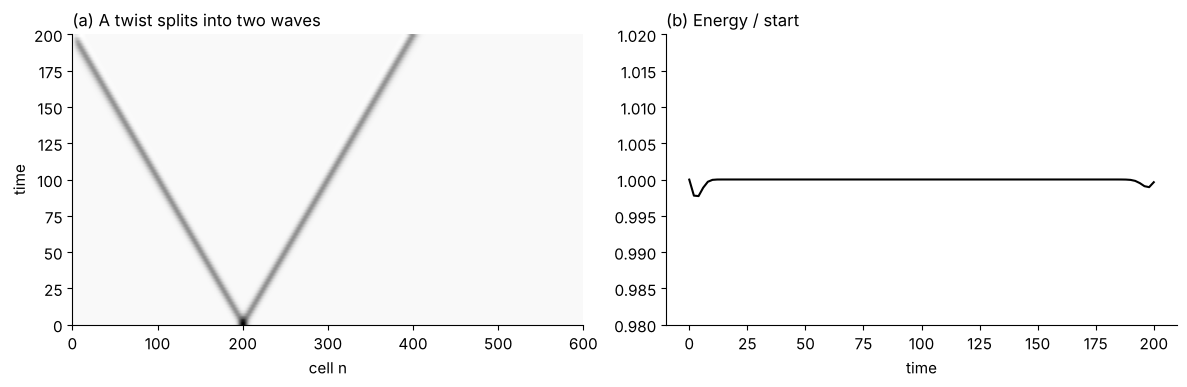

theory c = 1.000;  fitted speed = 0.9891 +/- 0.0008 (std. error)


In [5]:
def chain_run(N=600, I=1.0, k=16.0, R=0.5, dt=0.05, T=200.0, every=40, tc=np.inf):
    c = R/2*np.sqrt(k/I)
    n = np.arange(N)
    Om = np.exp(-((n - N/3)/6.0)**2)            # a twist pulse
    F = np.zeros(N - 1)
    out_t, out_Om, out_E = [], [], []
    for s in range(int(T/dt) + 1):
        if s % every == 0:
            out_t.append(s*dt); out_Om.append(Om.copy())
            out_E.append(0.5*I*(Om**2).sum() + 0.5*(F**2).sum()/k)
        F = (F*(1 - dt/(2*tc)) + dt*k*R/2*(Om[:-1] - Om[1:]))/(1 + dt/(2*tc))   # slip: a conductor
        Om[1:-1] += dt/I*R/2*(F[:-1] - F[1:])
    return c, np.array(out_t), np.array(out_Om), np.array(out_E)

c, t, Om, E = chain_run()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(Om, aspect="auto", origin="lower", extent=(0, Om.shape[1], 0, t[-1]), cmap="Greys")
ax[0].set_xlabel("cell n"); ax[0].set_ylabel("time"); ax[0].set_title("(a) A twist splits into two waves")
ax[1].plot(t, E/E[0]); ax[1].set_ylim(0.98, 1.02); ax[1].set_xlabel("time"); ax[1].set_title("(b) Energy / start")
plt.tight_layout(); plt.show()

# measure the speed: peak of the right-going half, then a straight-line fit
right = np.array([np.argmax(o[200:]) + 200 for o in Om])
use = (t > 10) & (t < 150)
fit = stats.linregress(t[use], right[use])
print(f"theory c = {c:.3f};  fitted speed = {fit.slope:.4f} +/- {fit.stderr:.4f} (std. error)")

**Course link: Linear Statistical Models.** The speed comes from a least-squares line through (time, peak position). Look at the result closely: the fitted speed misses $c = 1$ by more than ten standard errors. The standard error assumes independent noise around the line. Here the residuals are not noise. The peak sits on whole cells, so its position moves in steps. The pulse also spreads a little, because short waves travel slower than $c$ on a lattice (next cell). A small standard error does not mean a correct model.

**Try it 3.0.** Replace the peak by the centroid of the right-going half, `(o[200:]*np.arange(200, len(o))).sum()/o[200:].sum()`, and refit. Plot the residuals in both cases.

**Dispersion from a matrix.** Write the lattice as $\ddot{\boldsymbol\Omega} = -c^2 A\,\boldsymbol\Omega$, with $A$ the periodic second-difference matrix. Its eigenvalues give the frequencies: $\omega_m = 2c\,\sin(\pi m/N)$. Long waves travel at $c$; short waves are slower. That is lattice dispersion.

**Course link: Numerical Matrix Analysis.** $A$ is circulant. Every circulant matrix is diagonalized by the discrete Fourier transform, so its eigenvectors are sines and cosines.

largest gap, matrix eigenvalues vs 2c sin(k/2): 0.0


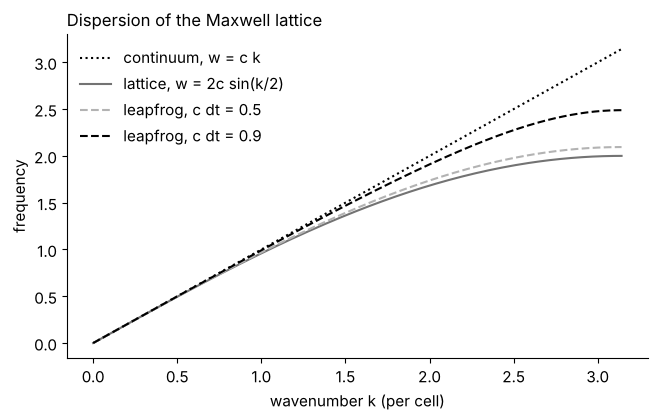

In [6]:
N = 64
A = linalg.circulant(np.r_[2, -1, np.zeros(N - 3), -1])
w_num = np.sqrt(np.clip(np.linalg.eigvalsh(A), 0, None))*c
kk = 2*np.pi*np.arange(N)/N
w_th = np.sort(2*c*np.abs(np.sin(kk/2)))
print("largest gap, matrix eigenvalues vs 2c sin(k/2):", np.abs(np.sort(w_num) - w_th).max().round(12))

k = np.linspace(0, np.pi, 200)
plt.plot(k, c*k, ":", label="continuum, w = c k")
plt.plot(k, 2*c*np.sin(k/2), label="lattice, w = 2c sin(k/2)")
for cdt in (0.5, 0.9):
    plt.plot(k, 2*c/cdt*np.arcsin(cdt*np.sin(k/2)), "--", label=f"leapfrog, c dt = {cdt}")
plt.xlabel("wavenumber k (per cell)"); plt.ylabel("frequency"); plt.legend(frameon=False); plt.title("Dispersion of the Maxwell lattice")
plt.show()

The leapfrog curves follow $\sin(\omega\,dt/2) = c\,dt\,\sin(k/2)$. Time stepping adds its own dispersion. At $c\,dt = 1$ (the "magic time step") the 1D scheme is exact.

**Try it 3.1 (stability).** Run `chain_run(dt=1.05, T=60, every=1)` so that $c\,dt > 1$. Watch the energy. Then derive the Courant limit $c\,dt \le 1$ by a von Neumann analysis: put $\Omega_n \propto g^s e^{ikn}$ and ask when $|g| \le 1$.

**Try it 3.2 (a conductor).** Let the idle particles slip: `chain_run(tc=1.5)`. The slip time $t_c$ acts as a conductivity $\sigma = \varepsilon/t_c$. Drive one end at frequency $\omega$ and measure how fast the wave decays. Compare with the skin depth $\delta = \sqrt{2/(\mu\sigma\omega)}$ when $\sigma \gg \varepsilon\omega$. Experiment 11 found 3.40 cells against 3.43 from theory.

---
## What comes next

Part 3 ends with Maxwell's lattice: rigid wheels, springy idle particles, and a lossless wave at speed $c$. The Vibrating-Fluid experiments then swap the wheels for vibrating shells:

- **Experiment 12** couples oval shells through an ideal fluid. The fluid shares mass between cells but gives no spring, so the waves form a narrow band with gaps and backward waves instead of a light line.
- **Experiment 13** adds a four-lobed tension around each shell and splits the two oval modes, like a crystal that splits light by polarization.

The full study notebook in the repository, `notebooks/maxwell_to_vibrating_cells.ipynb`, continues with those steps and adds nonlinear dynamics (Duffing shells, chaos, breathers) and statistics (equipartition, Maxwell's 1860 speed law, bootstrap, PCA, Fermi–Pasta–Ulam–Tsingou).

### Reading

- J. C. Maxwell, *On Physical Lines of Force*, Philosophical Magazine, 1861–62, Parts I–IV.
- D. M. Siegel, *Innovation in Maxwell's Electromagnetic Theory: Molecular Vortices, Displacement Current, and Light*, Cambridge University Press, 1991.
- A. Taflove and S. C. Hagness, *Computational Electrodynamics: The Finite-Difference Time-Domain Method*.